In [1]:

# ============================================
# NLP PROJECT
# PHASE 1: DATASET EXPLORATION
# ============================================

import pandas as pd
import numpy as np
from pathlib import Path


print("NLP TEXT PREPROCESSING PROJECT")
print("PHASE 1: DATASET EXPLORATION")


# Dataset paths
dataset_files = {
    "Train": "sentiment_train.csv",
    "Validation": "sentiment_validation.csv",
    "Test": "sentiment_test.csv"
}

# Check dataset files
for split, file_path in dataset_files.items():

    print(f"\n{split} Dataset")
    

    path = Path(file_path)

    if path.exists():

        df = pd.read_csv(path, sep=None, engine="python")

        print("File Found: YES")
        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())

        display(df.head(3))

    else:
        print("File Found: NO")
        print("Please check the file path.")


NLP TEXT PREPROCESSING PROJECT
PHASE 1: DATASET EXPLORATION

Train Dataset
File Found: YES
Shape: (45615, 2)
Columns: ['text', 'label']


,text,label
0,"""QT @user In the original draft of the 7th boo...",2
1,"""Ben Smith / Smith (concussion) remains out of...",1
2,Sorry bout the stream last night I crashed out...,1



Validation Dataset
File Found: YES
Shape: (2000, 2)
Columns: ['text', 'label']


,text,label
0,Dark Souls 3 April Launch Date Confirmed With ...,1
1,"""National hot dog day, national tequila day, t...",2
2,When girls become bandwagon fans of the Packer...,0



Test Dataset
File Found: YES
Shape: (12284, 2)
Columns: ['text', 'label']


,text,label
0,@user @user what do these '1/2 naked pics' hav...,1
1,OH: “I had a blue penis while I was this” [pla...,1
2,"@user @user That's coming, but I think the vic...",1


In [2]:

# ============================================
# PHASE 1 - STEP 2.1
# DATA QUALITY ANALYSIS
# ============================================

import pandas as pd
import numpy as np

# Load datasets
train_df = pd.read_csv(
    "sentiment_train.csv",
    sep=None,
    engine="python"
)

validation_df = pd.read_csv(
    "sentiment_validation.csv",
    sep=None,
    engine="python"
)

test_df = pd.read_csv(
    "sentiment_test.csv",
    sep=None,
    engine="python"
)

# Store datasets
datasets = {
    "Train": train_df,
    "Validation": validation_df,
    "Test": test_df
}

print("All datasets loaded successfully!")


All datasets loaded successfully!


In [3]:

# ============================================
# DATA QUALITY REPORT
# ============================================

quality_report = []

for split_name, df in datasets.items():

    missing_text = df["text"].isna().sum()

    missing_label = df["label"].isna().sum()

    duplicate_rows = df.duplicated().sum()

    duplicate_texts = df.duplicated(
        subset=["text"]
    ).sum()

    empty_texts = (
        df["text"]
        .fillna("")
        .astype(str)
        .str.strip()
        .eq("")
        .sum()
    )

    invalid_labels = (
        ~df["label"].isin([0, 1, 2])
    ).sum()

    quality_report.append({
        "Dataset": split_name,
        "Missing Text": missing_text,
        "Missing Label": missing_label,
        "Duplicate Rows": duplicate_rows,
        "Duplicate Texts": duplicate_texts,
        "Empty Texts": empty_texts,
        "Invalid Labels": invalid_labels
    })

# Display report
quality_df = pd.DataFrame(quality_report)

print("=" * 70)
print("DATA QUALITY ANALYSIS REPORT")
print("=" * 70)

display(quality_df)


DATA QUALITY ANALYSIS REPORT


,Dataset,Missing Text,Missing Label,Duplicate Rows,Duplicate Texts,Empty Texts,Invalid Labels
0,Train,0,0,26,29,0,0
1,Validation,0,0,0,0,0,0
2,Test,0,0,0,0,0,0


In [4]:

# ============================================
# STEP 2.3 - DUPLICATE TEXT INVESTIGATION
# ============================================

# Find repeated texts in training dataset

repeated_texts = (
    train_df.groupby("text")
    .agg(
        Occurrences=("label", "size"),
        Unique_Labels=("label", "nunique"),
        Labels=("label", lambda x: list(x.unique()))
    )
    .reset_index()
)

repeated_texts = repeated_texts[
    repeated_texts["Occurrences"] > 1
]

# Find texts having different sentiment labels

conflicting_texts = repeated_texts[
    repeated_texts["Unique_Labels"] > 1
]

print("=" * 60)
print("DUPLICATE TEXT INVESTIGATION")
print("=" * 60)

print("\nTotal Repeated Text Groups:",
      len(repeated_texts))

print("Texts with Conflicting Labels:",
      len(conflicting_texts))

print("\nRepeated Text Samples:")
display(repeated_texts.head(10))

print("\nConflicting Label Samples:")
display(conflicting_texts.head(10))


DUPLICATE TEXT INVESTIGATION

Total Repeated Text Groups: 25
Texts with Conflicting Labels: 3

Repeated Text Samples:


,text,Occurrences,Unique_Labels,Labels
1493,"""Charlie Rose with Bill Joy; Daniel Barenboim ...",2,1,[1]
1495,"""Charlie Rose with Desmond Tutu; Bill Joy (Oct...",2,1,[1]
2197,"""Facebook may have solved mobile, but Google i...",2,1,[1]
3587,"""I'm going to @user at US Bank Arena in Cincin...",2,1,[1]
5151,"""More meta-textually, Ant-Man may be the worst...",2,1,[0]
5557,"""October 2: New photo of Justin with Lenny Kra...",2,1,[1]
6083,"""RT @user Andy Rooney, 92, will make last appe...",2,1,[1]
10505,275 photos of 01 Oct 2014 Rock on Dandiya Nite...,2,1,[1]
18791,@user should we expect @user and the crew for ...,2,1,[1]
20115,After the Blood Moon comes the Pumpkin Sun,3,1,[1]



Conflicting Label Samples:


,text,Occurrences,Unique_Labels,Labels
20449,An emotionally intelligent organisation throug...,2,2,"[1, 2]"
22023,Buses to replace train services on Sunday as f...,2,2,"[2, 1]"
34782,Not making it to the main debate stage may not...,2,2,"[1, 0]"


In [5]:

# ============================================
# STEP 2.4 - CROSS DATASET DUPLICATE CHECK
# ============================================

train_texts = set(train_df["text"].dropna())
validation_texts = set(validation_df["text"].dropna())
test_texts = set(test_df["text"].dropna())

train_validation = train_texts & validation_texts
train_test = train_texts & test_texts
validation_test = validation_texts & test_texts

print("=" * 60)
print("CROSS DATASET DUPLICATE ANALYSIS")
print("=" * 60)

print("Train - Validation Overlap:",
      len(train_validation))

print("Train - Test Overlap:",
      len(train_test))

print("Validation - Test Overlap:",
      len(validation_test))


CROSS DATASET DUPLICATE ANALYSIS
Train - Validation Overlap: 0
Train - Test Overlap: 0
Validation - Test Overlap: 0


In [6]:

# ============================================
# PHASE 1 - STEP 3
# SENTIMENT DISTRIBUTION ANALYSIS
# ============================================

import matplotlib.pyplot as plt

# Label mapping
label_names = {
    0: "Negative",
    1: "Neutral",
    2: "Positive"
}

distribution_results = []

for split_name, df in datasets.items():

    counts = df["label"].value_counts().reindex(
        [0, 1, 2],
        fill_value=0
    )

    total = len(df)

    for label, count in counts.items():

        percentage = (count / total) * 100

        distribution_results.append({
            "Dataset": split_name,
            "Sentiment": label_names[label],
            "Count": count,
            "Percentage": round(percentage, 2)
        })

# Create DataFrame
distribution_df = pd.DataFrame(distribution_results)

# Count table
count_table = distribution_df.pivot(
    index="Dataset",
    columns="Sentiment",
    values="Count"
)

# Percentage table
percentage_table = distribution_df.pivot(
    index="Dataset",
    columns="Sentiment",
    values="Percentage"
)

# Maintain dataset order
dataset_order = ["Train", "Validation", "Test"]
sentiment_order = ["Negative", "Neutral", "Positive"]

count_table = count_table.reindex(
    index=dataset_order,
    columns=sentiment_order
)

percentage_table = percentage_table.reindex(
    index=dataset_order,
    columns=sentiment_order
)

print("=" * 65)
print("SENTIMENT COUNT REPORT")
print("=" * 65)

display(count_table)

print("\nSENTIMENT PERCENTAGE REPORT")
display(percentage_table)


SENTIMENT COUNT REPORT


Sentiment,Negative,Neutral,Positive
Dataset,,,
Train,7093,20673,17849
Validation,312,869,819
Test,3972,5937,2375



SENTIMENT PERCENTAGE REPORT


Sentiment,Negative,Neutral,Positive
Dataset,,,
Train,15.55,45.32,39.13
Validation,15.60,43.45,40.95
Test,32.33,48.33,19.33


<Figure size 1000x500 with 0 Axes>

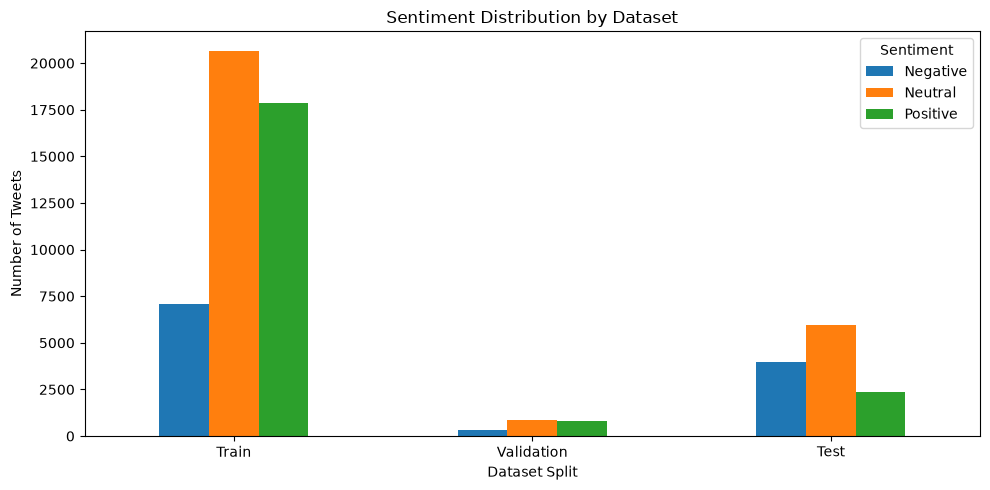

In [7]:

# ============================================
# SENTIMENT DISTRIBUTION BAR CHART
# ============================================

plt.figure(figsize=(10, 5))

count_table.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Sentiment Distribution by Dataset")
plt.xlabel("Dataset Split")
plt.ylabel("Number of Tweets")

plt.xticks(rotation=0)
plt.legend(title="Sentiment")

plt.tight_layout()
plt.show()


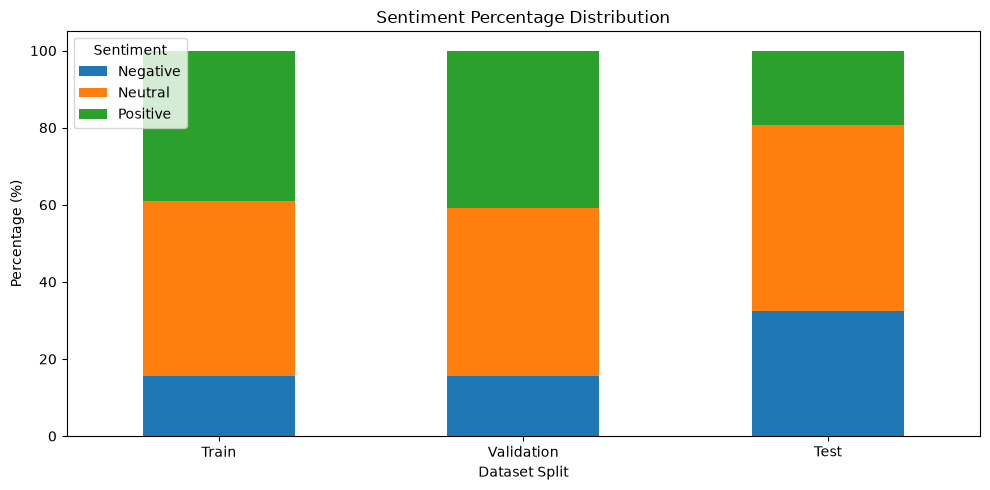

In [8]:

# ============================================
# SENTIMENT PERCENTAGE COMPARISON
# ============================================

percentage_table.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 5)
)

plt.title("Sentiment Percentage Distribution")
plt.xlabel("Dataset Split")
plt.ylabel("Percentage (%)")

plt.xticks(rotation=0)
plt.legend(title="Sentiment")

plt.tight_layout()
plt.show()


In [9]:

# ============================================
# PHASE 1 - STEP 4
# TEXT LENGTH ANALYSIS
# ============================================

# Combine all dataset splits for analysis

combined_df = pd.concat(
    [
        df.assign(Dataset=split)
        for split, df in datasets.items()
    ],
    ignore_index=True
)

# Calculate character count
combined_df["char_count"] = (
    combined_df["text"]
    .astype(str)
    .str.len()
)

# Calculate word count
combined_df["word_count"] = (
    combined_df["text"]
    .astype(str)
    .str.split()
    .str.len()
)

# Map sentiment labels
label_names = {
    0: "Negative",
    1: "Neutral",
    2: "Positive"
}

combined_df["sentiment"] = (
    combined_df["label"].map(label_names)
)

print("Text length features created successfully!")

display(
    combined_df[
        ["text", "label", "sentiment",
         "char_count", "word_count"]
    ].head(10)
)


Text length features created successfully!


,text,label,sentiment,char_count,word_count
0,"""QT @user In the original draft of the 7th boo...",2,Positive,119,18
1,"""Ben Smith / Smith (concussion) remains out of...",1,Neutral,84,14
2,Sorry bout the stream last night I crashed out...,1,Neutral,124,24
3,Chase Headley's RBI double in the 8th inning o...,1,Neutral,139,23
4,@user Alciato: Bee will invest 150 million in ...,2,Positive,114,21
5,@user LIT MY MUM 'Kerry the louboutins I wonde...,2,Positive,101,17
6,"""\"""""""" SOUL TRAIN\"""""""" OCT 27 HALLOWEEN SPECIA...",2,Positive,145,23
7,So disappointed in wwe summerslam! I want to s...,0,Negative,78,15
8,"""This is the last Sunday w/o football .....,NF...",2,Positive,61,11
9,@user @user CENA & AJ sitting in a tree K-I-S-...,1,Neutral,127,24


In [10]:

# ============================================
# TEXT LENGTH STATISTICAL SUMMARY
# ============================================

length_summary = (
    combined_df.groupby("Dataset")
    .agg(
        Total_Tweets=("text", "count"),

        Average_Characters=("char_count", "mean"),
        Median_Characters=("char_count", "median"),

        Minimum_Characters=("char_count", "min"),
        Maximum_Characters=("char_count", "max"),

        Average_Words=("word_count", "mean"),
        Median_Words=("word_count", "median"),

        Minimum_Words=("word_count", "min"),
        Maximum_Words=("word_count", "max")
    )
    .round(2)
)

print("=" * 75)
print("TEXT LENGTH STATISTICAL SUMMARY")
print("=" * 75)

display(length_summary)


TEXT LENGTH STATISTICAL SUMMARY


,Total_Tweets,Average_Characters,Median_Characters,Minimum_Characters,Maximum_Characters,Average_Words,Median_Words,Minimum_Words,Maximum_Words
Dataset,,,,,,,,,
Test,12284,91.35,95.0,6,141,14.86,15.0,1,32
Train,45615,106.93,113.0,10,200,19.24,20.0,1,35
Validation,2000,107.54,113.0,28,170,19.44,20.0,4,31


In [11]:

# ============================================
# SENTIMENT-WISE TEXT LENGTH ANALYSIS
# ============================================

sentiment_length = (
    combined_df.groupby(
        ["Dataset", "sentiment"]
    )
    .agg(
        Average_Words=("word_count", "mean"),
        Median_Words=("word_count", "median"),
        Average_Characters=("char_count", "mean"),
        Total_Tweets=("text", "count")
    )
    .round(2)
)

print("=" * 70)
print("SENTIMENT-WISE TEXT LENGTH REPORT")
print("=" * 70)

display(sentiment_length)


SENTIMENT-WISE TEXT LENGTH REPORT


Average_Words  Median_Words  Average_Characters  \
Dataset    sentiment                                                    
Test       Negative           16.80          17.0              101.38   
           Neutral            13.99          14.0               87.54   
           Positive           13.78          13.0               84.07   
Train      Negative           20.22          21.0              112.12   
           Neutral            18.98          19.0              105.99   
           Positive           19.15          19.0              105.96   
Validation Negative           20.30          21.0              112.35   
           Neutral            19.22          20.0              106.67   
           Positive           19.36          20.0              106.63   

                      Total_Tweets  
Dataset    sentiment                
Test       Negative           3972  
           Neutral            5937  
           Positive           2375  
Train      Negative           7093  
           Neutral           20673  
           Positive          17849  
Validation Negative            312  
           Neutral             869  
           Positive            819

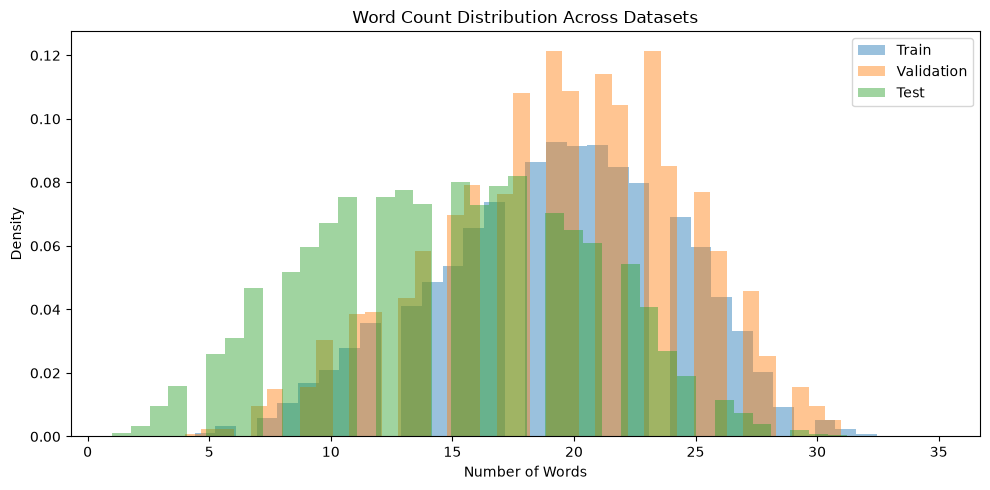

In [12]:

# ============================================
# WORD COUNT DISTRIBUTION
# ============================================

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

for split in ["Train", "Validation", "Test"]:

    data = combined_df.loc[
        combined_df["Dataset"] == split,
        "word_count"
    ]

    plt.hist(
        data,
        bins=40,
        alpha=0.45,
        density=True,
        label=split
    )

plt.title("Word Count Distribution Across Datasets")
plt.xlabel("Number of Words")
plt.ylabel("Density")

plt.legend()
plt.tight_layout()
plt.show()


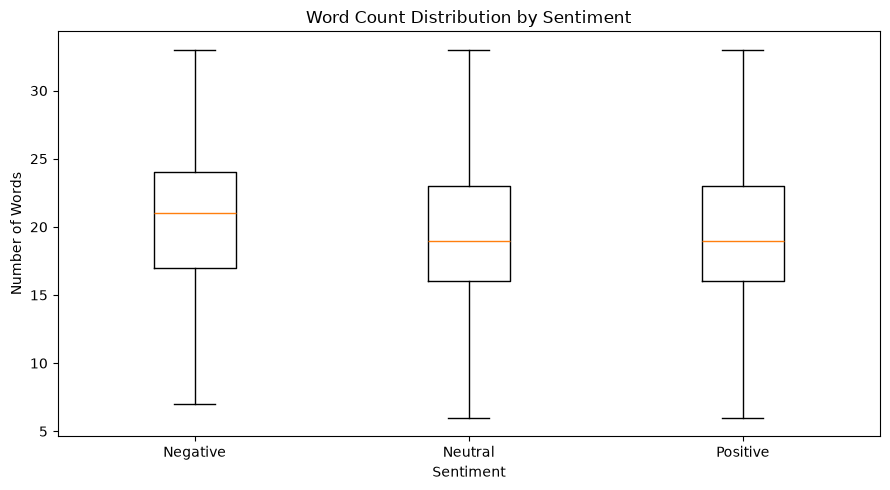

In [13]:

# ============================================
# SENTIMENT-WISE WORD COUNT BOXPLOT
# ============================================

train_only = combined_df[
    combined_df["Dataset"] == "Train"
]

sentiments = ["Negative", "Neutral", "Positive"]

word_data = [
    train_only.loc[
        train_only["sentiment"] == sentiment,
        "word_count"
    ]
    for sentiment in sentiments
]

plt.figure(figsize=(9, 5))

plt.boxplot(
    word_data,
    tick_labels=sentiments,
    showfliers=False
)

plt.title("Word Count Distribution by Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Number of Words")

plt.tight_layout()
plt.show()


In [14]:
print(length_summary.loc["Validation"].to_string())

Total_Tweets          2000.00
Average_Characters     107.54
Median_Characters      113.00
Minimum_Characters      28.00
Maximum_Characters     170.00
Average_Words           19.44
Median_Words            20.00
Minimum_Words            4.00
Maximum_Words           31.00


In [15]:
%pip install nltk

  Using cached nltk-3.10.4-py3-none-any.whl.metadata (5.0 kB)
  Using cached defusedxml-0.7.1-py2.py3-none-any.whl.metadata (32 kB)
  Using cached click-8.5.0-py3-none-any.whl.metadata (2.6 kB)
  Using cached regex-2026.9.29-cp312-cp312-win_amd64.whl.metadata (41 kB)
Using cached nltk-3.10.4-py3-none-any.whl (1.7 MB)
Using cached regex-2026.9.29-cp312-cp312-win_amd64.whl (280 kB)
Using cached click-8.5.0-py3-none-any.whl (125 kB)
Using cached defusedxml-0.7.1-py2.py3-none-any.whl (25 kB)

   ---------------------------------------- 0/4 [regex]

Note: you may need to restart the kernel to use updated packages.


ERROR: Could not install packages due to an OSError: [WinError 5] Access is denied: 'c:\\Program Files\\Python312\\Lib\\site-packages\\regex'
Consider using the `--user` option or check the permissions.


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [16]:
import sys

print("Current Python Path:")
print(sys.executable)

Current Python Path:
c:\Program Files\Python312\python.exe


In [1]:
import sys
import nltk

print("Python Path:", sys.executable)
print("NLTK Version:", nltk.__version__)

nltk.download("stopwords")

print("Environment Setup Successful!")

Python Path: d:\NLP-Text-Preprocessing-Benchmark\.venv\Scripts\python.exe
NLTK Version: 3.10.4
Environment Setup Successful!


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Acer\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [2]:
import sys
import importlib.util
import subprocess

required_packages = [
    "pandas",
    "numpy",
    "matplotlib",
    "nltk"
]

missing_packages = [
    package for package in required_packages
    if importlib.util.find_spec(package) is None
]

if missing_packages:
    subprocess.check_call([
        sys.executable,
        "-m",
        "pip",
        "install",
        *missing_packages
    ])

print("All required libraries are ready!")

All required libraries are ready!


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

train_df = pd.read_csv(
    "sentiment_train.csv",
    sep=None,
    engine="python"
)

validation_df = pd.read_csv(
    "sentiment_validation.csv",
    sep=None,
    engine="python"
)

test_df = pd.read_csv(
    "sentiment_test.csv",
    sep=None,
    engine="python"
)

datasets = {
    "Train": train_df,
    "Validation": validation_df,
    "Test": test_df
}

print("Dataset Loaded Successfully!")

print("Train:", train_df.shape)
print("Validation:", validation_df.shape)
print("Test:", test_df.shape)

Dataset Loaded Successfully!
Train: (45615, 2)
Validation: (2000, 2)
Test: (12284, 2)


In [4]:
import re
import nltk

from collections import Counter
from nltk.corpus import stopwords

nltk.download("stopwords")

stop_words = set(stopwords.words("english"))

# Preserve sentiment-related words
stop_words.difference_update({
    "no", "nor", "not", "never"
})

# Remove dataset-specific noise
stop_words.update({
    "user", "rt", "amp",
    "http", "https", "www"
})

print("Total Stopwords:", len(stop_words))
print("Stopwords loaded successfully!")

Total Stopwords: 201
Stopwords loaded successfully!


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Acer\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [5]:
# ============================================
# TOKEN EXTRACTION
# ============================================

def extract_tokens(text):

    text = str(text).lower()

    # Remove URLs
    text = re.sub(
        r"https?://\S+|www\.\S+",
        " ",
        text
    )

    # Extract words
    tokens = re.findall(
        r"[a-z]+(?:'[a-z]+)?",
        text
    )

    return tokens


train_tokens = []

for text in train_df["text"].dropna():

    tokens = extract_tokens(text)

    train_tokens.extend(tokens)


print("Total Extracted Tokens:", len(train_tokens))
print("Sample Tokens:", train_tokens[:30])

Total Extracted Tokens: 880183
Sample Tokens: ['qt', 'user', 'in', 'the', 'original', 'draft', 'of', 'the', 'th', 'book', 'remus', 'lupin', 'survived', 'the', 'battle', 'of', 'hogwarts', 'happybirthdayremuslupin', 'ben', 'smith', 'smith', 'concussion', 'remains', 'out', 'of', 'the', 'lineup', 'thursday', 'curtis', 'nhl']


In [6]:
# ============================================
# RAW WORD FREQUENCY
# ============================================

raw_frequency = Counter(train_tokens)

raw_frequency_df = pd.DataFrame(
    raw_frequency.most_common(20),
    columns=["Word", "Frequency"]
)

print("Top 20 Raw Frequent Words:")

display(raw_frequency_df)

Top 20 Raw Frequent Words:


,Word,Frequency
0,the,38017
1,to,20953
2,user,16840
3,in,13716
4,i,13620
5,on,13119
6,a,13051
7,and,12701
8,of,10900
9,u,10133


In [7]:
# ============================================
# WORD FREQUENCY AFTER STOPWORD REMOVAL
# ============================================

filtered_tokens = [
    word
    for word in train_tokens
    if word not in stop_words and len(word) > 1
]

filtered_frequency = Counter(filtered_tokens)

filtered_frequency_df = pd.DataFrame(
    filtered_frequency.most_common(20),
    columns=["Word", "Frequency"]
)

print("Total Tokens Before Filtering:", len(train_tokens))

print("Total Tokens After Filtering:", len(filtered_tokens))

print("\nTop 20 Meaningful Words:")

display(filtered_frequency_df)

Total Tokens Before Filtering: 880183
Total Tokens After Filtering: 508060

Top 20 Meaningful Words:


,Word,Frequency
0,tomorrow,7257
1,may,6683
2,th,5892
3,day,3871
4,st,3141
5,going,3032
6,not,3001
7,night,2975
8,see,2822
9,friday,2729


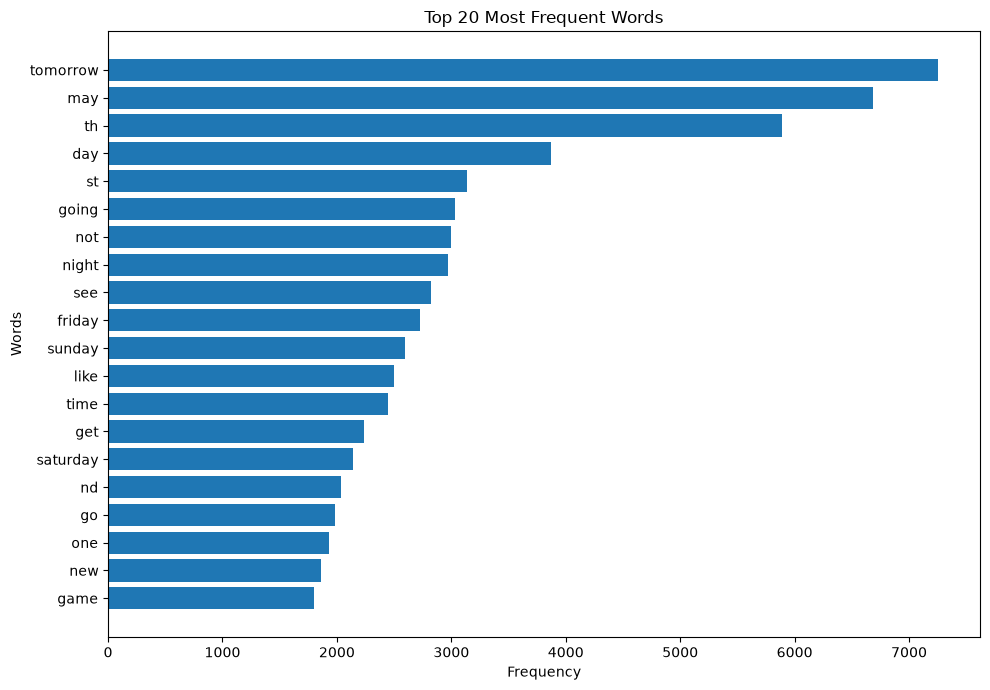

In [8]:
# ============================================
# TOP 20 WORD FREQUENCY CHART
# ============================================

top_words = filtered_frequency_df.sort_values(
    by="Frequency",
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_words["Word"],
    top_words["Frequency"]
)

plt.title("Top 20 Most Frequent Words")
plt.xlabel("Frequency")
plt.ylabel("Words")

plt.tight_layout()
plt.show()

In [9]:
# ============================================
# SENTIMENT-WISE WORD FREQUENCY
# ============================================

label_names = {
    0: "Negative",
    1: "Neutral",
    2: "Positive"
}

for label, sentiment in label_names.items():

    sentiment_texts = train_df.loc[
        train_df["label"] == label,
        "text"
    ]

    sentiment_tokens = []

    for text in sentiment_texts.dropna():

        tokens = extract_tokens(text)

        sentiment_tokens.extend([
            word for word in tokens
            if word not in stop_words and len(word) > 1
        ])

    sentiment_frequency = Counter(sentiment_tokens)

    result = pd.DataFrame(
        sentiment_frequency.most_common(15),
        columns=["Word", "Frequency"]
    )

    print(f"\nTOP 15 WORDS - {sentiment.upper()}")

    display(result)


TOP 15 WORDS - NEGATIVE


,Word,Frequency
0,may,1571
1,not,946
2,tomorrow,919
3,th,729
4,like,590
5,st,548
6,day,441
7,going,428
8,no,419
9,get,370



TOP 15 WORDS - NEUTRAL


,Word,Frequency
0,may,2903
1,th,2889
2,tomorrow,2881
3,st,1415
4,going,1320
5,day,1309
6,not,1296
7,night,1262
8,sunday,1190
9,friday,1186



TOP 15 WORDS - POSITIVE


,Word,Frequency
0,tomorrow,3457
1,th,2274
2,may,2209
3,day,2121
4,see,1562
5,night,1436
6,going,1284
7,friday,1255
8,st,1178
9,good,1154


In [11]:

# =====================================================
# PHASE 1: DATASET EXPLORATION
# FINAL SUMMARY REPORT (STEP 1 - STEP 5)
# =====================================================

import pandas as pd
import re
from collections import Counter

print("\n" + "=" * 65)
print("NLP PROJECT - PHASE 1 FINAL SUMMARY")
print("=" * 65)

# 1. Dataset Overview
datasets = {
    "Train": train_df,
    "Validation": validation_df,
    "Test": test_df
}

print("\n[1] DATASET OVERVIEW")

for name, df in datasets.items():
    print(f"{name}: {df.shape[0]} samples, {df.shape[1]} columns")

print("Total Samples:",
      sum(len(df) for df in datasets.values()))


# 2. Data Quality Summary
print("\n[2] DATA QUALITY SUMMARY")

quality = []

for name, df in datasets.items():
    quality.append({
        "Dataset": name,
        "Missing Values": df.isna().sum().sum(),
        "Duplicate Rows": df.duplicated().sum(),
        "Empty Texts": df["text"].fillna("").astype(str).str.strip().eq("").sum(),
        "Invalid Labels": (~df["label"].isin([0, 1, 2])).sum()
    })

display(pd.DataFrame(quality))


# 3. Duplicate Investigation
print("\n[3] DUPLICATE INVESTIGATION")

repeated = train_df.groupby("text").agg(
    Occurrences=("label", "size"),
    Unique_Labels=("label", "nunique")
)

repeated = repeated[repeated["Occurrences"] > 1]

print("Repeated Text Groups:", len(repeated))
print("Conflicting Label Groups:",
      (repeated["Unique_Labels"] > 1).sum())


# 4. Cross Dataset Overlap
print("\n[4] CROSS DATASET OVERLAP")

sets = {
    name: set(df["text"].dropna())
    for name, df in datasets.items()
}

print("Train - Validation:",
      len(sets["Train"] & sets["Validation"]))

print("Train - Test:",
      len(sets["Train"] & sets["Test"]))

print("Validation - Test:",
      len(sets["Validation"] & sets["Test"]))


# 5. Sentiment Distribution
print("\n[5] SENTIMENT DISTRIBUTION")

labels = {0: "Negative", 1: "Neutral", 2: "Positive"}

sentiment_summary = []

for name, df in datasets.items():
    for label, sentiment in labels.items():
        count = (df["label"] == label).sum()

        sentiment_summary.append({
            "Dataset": name,
            "Sentiment": sentiment,
            "Count": count,
            "Percentage": round(count / len(df) * 100, 2)
        })

display(pd.DataFrame(sentiment_summary))


# 6. Text Length Summary
print("\n[6] TEXT LENGTH SUMMARY")

length_results = []

for name, df in datasets.items():
    text = df["text"].fillna("").astype(str)

    length_results.append({
        "Dataset": name,
        "Average Characters": round(text.str.len().mean(), 2),
        "Average Words": round(text.str.split().str.len().mean(), 2),
        "Median Words": text.str.split().str.len().median(),
        "Maximum Words": text.str.split().str.len().max()
    })

display(pd.DataFrame(length_results))


# 7. Word Frequency Summary
print("\n[7] WORD FREQUENCY SUMMARY")

def summary_tokens(text):
    text = str(text).lower()
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    return re.findall(r"[a-z]+(?:'[a-z]+)?", text)

stop_words = globals().get("stop_words", set())

if not stop_words:
    try:
        from nltk.corpus import stopwords
        stop_words = set(stopwords.words("english"))
    except LookupError:
        stop_words = set()

stop_words = stop_words - {"no", "nor", "not", "never"}
stop_words.update({"user", "rt", "amp", "http", "https", "www"})

all_tokens = []

for text in train_df["text"].dropna():
    all_tokens.extend(summary_tokens(text))

filtered = [
    word for word in all_tokens
    if word not in stop_words and len(word) > 1
]

print("Total Raw Tokens:", len(all_tokens))
print("Filtered Tokens:", len(filtered))
print("Unique Words:", len(set(filtered)))

print("\nTOP 10 MEANINGFUL WORDS")

display(pd.DataFrame(
    Counter(filtered).most_common(10),
    columns=["Word", "Frequency"]
))


# 8. Final Progress Status
print("\n" + "=" * 65)
print("PHASE 1 PROGRESS STATUS")
print("=" * 65)

progress = {
    "Dataset Loading": "COMPLETED",
    "Data Quality Analysis": "COMPLETED",
    "Duplicate Investigation": "COMPLETED",
    "Cross Dataset Analysis": "COMPLETED",
    "Sentiment Distribution": "COMPLETED",
    "Text Length Analysis": "COMPLETED",
    "Word Frequency Analysis": "COMPLETED",
    "Word Cloud Visualization": "PENDING"
}

for task, status in progress.items():
    print(f"{task:<35}: {status}")

print("\nCURRENT STATUS: PHASE 1 IN PROGRESS")
print("Next Task: Word Cloud Visualization")
print("=" * 65)



NLP PROJECT - PHASE 1 FINAL SUMMARY

[1] DATASET OVERVIEW
Train: 45615 samples, 2 columns
Validation: 2000 samples, 2 columns
Test: 12284 samples, 2 columns
Total Samples: 59899

[2] DATA QUALITY SUMMARY


,Dataset,Missing Values,Duplicate Rows,Empty Texts,Invalid Labels
0,Train,0,26,0,0
1,Validation,0,0,0,0
2,Test,0,0,0,0



[3] DUPLICATE INVESTIGATION
Repeated Text Groups: 25
Conflicting Label Groups: 3

[4] CROSS DATASET OVERLAP
Train - Validation: 0
Train - Test: 0
Validation - Test: 0

[5] SENTIMENT DISTRIBUTION


,Dataset,Sentiment,Count,Percentage
0,Train,Negative,7093,15.55
1,Train,Neutral,20673,45.32
2,Train,Positive,17849,39.13
3,Validation,Negative,312,15.60
4,Validation,Neutral,869,43.45
5,Validation,Positive,819,40.95
6,Test,Negative,3972,32.33
7,Test,Neutral,5937,48.33
8,Test,Positive,2375,19.33



[6] TEXT LENGTH SUMMARY


,Dataset,Average Characters,Average Words,Median Words,Maximum Words
0,Train,106.93,19.24,20.0,35
1,Validation,107.54,19.44,20.0,31
2,Test,91.35,14.86,15.0,32



[7] WORD FREQUENCY SUMMARY
Total Raw Tokens: 880183
Filtered Tokens: 508060
Unique Words: 42199

TOP 10 MEANINGFUL WORDS


,Word,Frequency
0,tomorrow,7257
1,may,6683
2,th,5892
3,day,3871
4,st,3141
5,going,3032
6,not,3001
7,night,2975
8,see,2822
9,friday,2729



PHASE 1 PROGRESS STATUS
Dataset Loading                    : COMPLETED
Data Quality Analysis              : COMPLETED
Duplicate Investigation            : COMPLETED
Cross Dataset Analysis             : COMPLETED
Sentiment Distribution             : COMPLETED
Text Length Analysis               : COMPLETED
Word Frequency Analysis            : COMPLETED
Word Cloud Visualization           : PENDING

CURRENT STATUS: PHASE 1 IN PROGRESS
Next Task: Word Cloud Visualization


In [12]:
%pip install wordcloud

Note: you may need to restart the kernel to use updated packages.


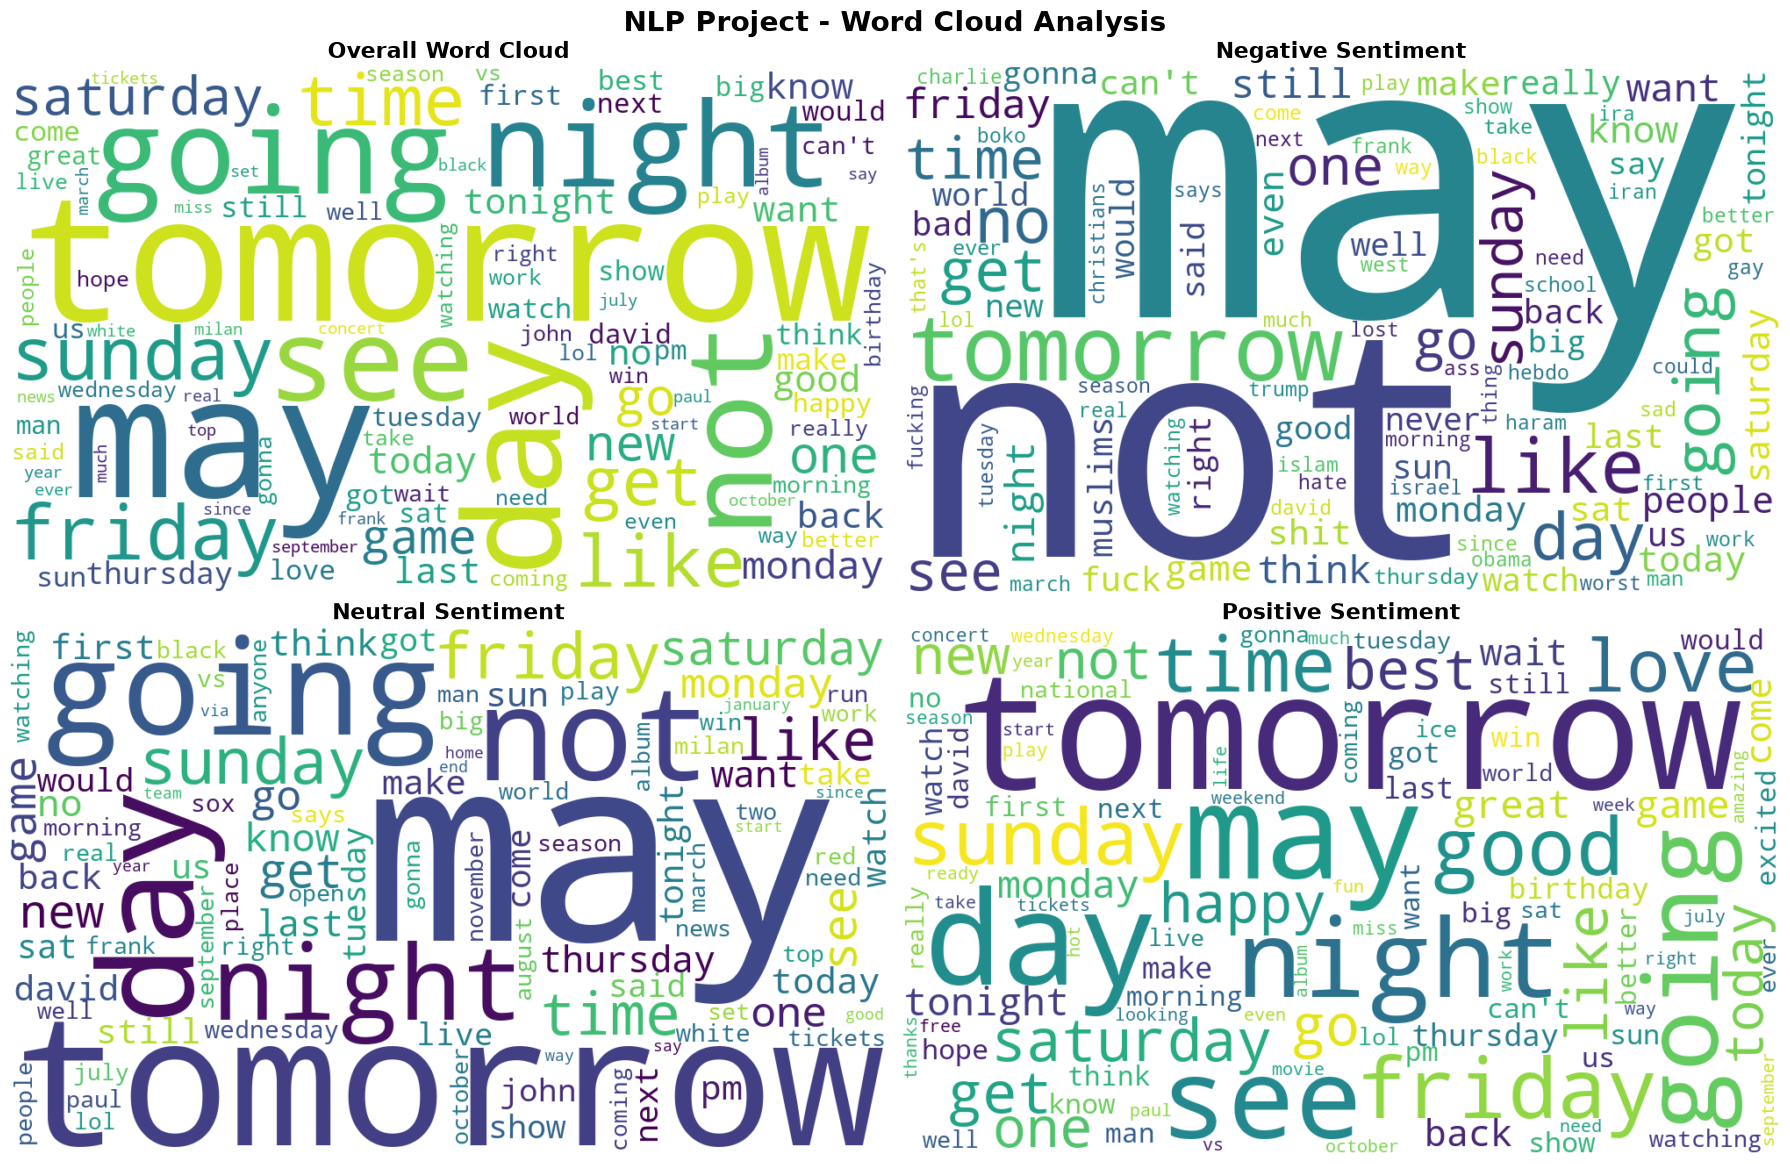


WORD CLOUD ANALYSIS SUMMARY

Overall Word Cloud
Unique Words: 42195
Top 10 Words:
[('tomorrow', 7257), ('may', 6683), ('day', 3871), ('going', 3032), ('not', 3001), ('night', 2975), ('see', 2822), ('friday', 2729), ('sunday', 2593), ('like', 2495)]

Negative Sentiment
Unique Words: 14354
Top 10 Words:
[('may', 1571), ('not', 946), ('tomorrow', 919), ('like', 590), ('day', 441), ('going', 428), ('no', 419), ('get', 370), ('time', 348), ('sunday', 325)]

Neutral Sentiment
Unique Words: 27747
Top 10 Words:
[('may', 2903), ('tomorrow', 2881), ('going', 1320), ('day', 1309), ('not', 1296), ('night', 1262), ('sunday', 1190), ('friday', 1186), ('time', 1037), ('like', 994)]

Positive Sentiment
Unique Words: 23085
Top 10 Words:
[('tomorrow', 3457), ('may', 2209), ('day', 2121), ('see', 1562), ('night', 1436), ('going', 1284), ('friday', 1255), ('good', 1154), ('sunday', 1078), ('time', 1062)]


In [13]:

# ============================================
# PHASE 1 - STEP 6
# WORD CLOUD VISUALIZATION
# ============================================

import re
import nltk
import matplotlib.pyplot as plt

from collections import Counter
from nltk.corpus import stopwords
from wordcloud import WordCloud

# Load stopwords
nltk.download("stopwords", quiet=True)

visual_stop_words = set(
    stopwords.words("english")
)

# Preserve important sentiment words
visual_stop_words.difference_update({
    "no", "nor", "not", "never"
})

# Remove dataset-specific noise
visual_stop_words.update({
    "user", "rt", "amp",
    "http", "https", "www",
    "th", "st", "nd", "rd"
})


# Token extraction
def wordcloud_tokens(text):

    text = str(text).lower()

    text = re.sub(
        r"https?://\S+|www\.\S+",
        " ",
        text
    )

    tokens = re.findall(
        r"[a-z]+(?:'[a-z]+)?",
        text
    )

    return [
        word for word in tokens
        if word not in visual_stop_words
        and len(word) > 1
    ]


# Generate word frequencies
def generate_frequency(texts):

    tokens = []

    for text in texts.dropna():
        tokens.extend(wordcloud_tokens(text))

    return Counter(tokens)


# Overall frequency
overall_frequency = generate_frequency(
    train_df["text"]
)


# Sentiment-wise frequency
sentiment_frequencies = {}

label_names = {
    0: "Negative",
    1: "Neutral",
    2: "Positive"
}

for label, sentiment in label_names.items():

    sentiment_texts = train_df.loc[
        train_df["label"] == label,
        "text"
    ]

    sentiment_frequencies[sentiment] = (
        generate_frequency(sentiment_texts)
    )


# ============================================
# CREATE FOUR WORD CLOUDS
# ============================================

cloud_data = [
    ("Overall Word Cloud", overall_frequency),
    ("Negative Sentiment", sentiment_frequencies["Negative"]),
    ("Neutral Sentiment", sentiment_frequencies["Neutral"]),
    ("Positive Sentiment", sentiment_frequencies["Positive"])
]

fig, axes = plt.subplots(
    2, 2,
    figsize=(18, 12)
)

for ax, (title, frequency) in zip(
    axes.flatten(), cloud_data
):

    wordcloud = WordCloud(
        width=1000,
        height=600,
        background_color="white",
        max_words=100,
        collocations=False
    ).generate_from_frequencies(frequency)

    ax.imshow(
        wordcloud,
        interpolation="bilinear"
    )

    ax.set_title(
        title,
        fontsize=16,
        fontweight="bold"
    )

    ax.axis("off")


plt.suptitle(
    "NLP Project - Word Cloud Analysis",
    fontsize=20,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


# ============================================
# TOP WORDS SUMMARY
# ============================================

print("\nWORD CLOUD ANALYSIS SUMMARY")

for title, frequency in cloud_data:

    print(f"\n{title}")

    print("Unique Words:", len(frequency))

    print("Top 10 Words:")

    print(frequency.most_common(10))


In [14]:

# =====================================================
# NLP TEXT PREPROCESSING PROJECT
# PHASE 1: FINAL VERIFICATION REPORT
# =====================================================

print("\n" + "=" * 65)
print("PHASE 1 - FINAL VERIFICATION REPORT")
print("=" * 65)

# Check completed tasks
checks = {
    "Dataset Loading": all(
        x in globals()
        for x in ["train_df", "validation_df", "test_df"]
    ),

    "Data Quality Analysis": "quality_df" in globals(),

    "Duplicate Investigation": all(
        x in globals()
        for x in ["repeated_texts", "conflicting_texts"]
    ),

    "Cross Dataset Analysis": "overlap_results" in globals(),

    "Sentiment Distribution": all(
        x in globals()
        for x in ["count_table", "percentage_table"]
    ),

    "Text Length Analysis": all(
        x in globals()
        for x in ["combined_df", "length_summary", "sentiment_length"]
    ),

    "Word Frequency Analysis": all(
        x in globals()
        for x in ["raw_frequency_df", "filtered_frequency_df"]
    ),

    "Word Cloud Visualization": all(
        x in globals()
        for x in [
            "overall_frequency",
            "sentiment_frequencies",
            "cloud_data"
        ]
    )
}

# Display task status
print("\n[1] TASK COMPLETION STATUS")

for task, completed in checks.items():

    status = "COMPLETED" if completed else "PENDING"

    print(f"{task:<35}: {status}")


# Dataset summary
if checks["Dataset Loading"]:

    print("\n[2] DATASET SUMMARY")

    total_samples = (
        len(train_df)
        + len(validation_df)
        + len(test_df)
    )

    print("Training Samples:", len(train_df))
    print("Validation Samples:", len(validation_df))
    print("Testing Samples:", len(test_df))
    print("Total Samples:", total_samples)


# Duplicate summary
if checks["Duplicate Investigation"]:

    print("\n[3] DUPLICATE SUMMARY")

    print("Repeated Text Groups:", len(repeated_texts))
    print("Conflicting Label Groups:", len(conflicting_texts))


# Sentiment summary
if checks["Sentiment Distribution"]:

    print("\n[4] SENTIMENT DISTRIBUTION")

    display(count_table)

    print("Test Dataset Distribution:")

    display(percentage_table.loc[["Test"]])


# Text length summary
if checks["Text Length Analysis"]:

    print("\n[5] TEXT LENGTH SUMMARY")

    display(length_summary)


# Word frequency summary
if checks["Word Frequency Analysis"]:

    print("\n[6] TOP 10 FREQUENT WORDS")

    display(filtered_frequency_df.head(10))


# Word cloud summary
if checks["Word Cloud Visualization"]:

    print("\n[7] WORD CLOUD SUMMARY")

    print("Overall Unique Words:",
          len(overall_frequency))

    for sentiment, frequency in sentiment_frequencies.items():

        print(f"\n{sentiment} Unique Words:",
              len(frequency))

        print("Top 5 Words:",
              frequency.most_common(5))


# Final completion status
print("\n" + "=" * 65)

completed_tasks = sum(checks.values())
total_tasks = len(checks)

print(f"Completed Tasks: {completed_tasks}/{total_tasks}")

if all(checks.values()):

    print("PHASE 1 STATUS: COMPLETED")

    print("All dataset exploration tasks verified.")

    print("NEXT PHASE: BASIC TEXT PREPROCESSING")

else:

    print("PHASE 1 STATUS: INCOMPLETE")

    print("Please check the pending tasks above.")

print("=" * 65)



PHASE 1 - FINAL VERIFICATION REPORT

[1] TASK COMPLETION STATUS
Dataset Loading                    : COMPLETED
Data Quality Analysis              : COMPLETED
Duplicate Investigation            : COMPLETED
Cross Dataset Analysis             : COMPLETED
Sentiment Distribution             : COMPLETED
Text Length Analysis               : COMPLETED
Word Frequency Analysis            : COMPLETED
Word Cloud Visualization           : COMPLETED

[2] DATASET SUMMARY
Training Samples: 45615
Validation Samples: 2000
Testing Samples: 12284
Total Samples: 59899

[3] DUPLICATE SUMMARY
Repeated Text Groups: 25
Conflicting Label Groups: 3

[4] SENTIMENT DISTRIBUTION


Sentiment,Negative,Neutral,Positive
Dataset,,,
Train,7093,20673,17849
Validation,312,869,819
Test,3972,5937,2375


Test Dataset Distribution:


Sentiment,Negative,Neutral,Positive
Dataset,,,
Test,32.33,48.33,19.33



[5] TEXT LENGTH SUMMARY


,Total_Tweets,Average_Characters,Median_Characters,Minimum_Characters,Maximum_Characters,Average_Words,Median_Words,Minimum_Words,Maximum_Words
Dataset,,,,,,,,,
Train,45615,106.93,113.0,10,200,19.24,20.0,1,35
Validation,2000,107.54,113.0,28,170,19.44,20.0,4,31
Test,12284,91.35,95.0,6,141,14.86,15.0,1,32



[6] TOP 10 FREQUENT WORDS


,Word,Frequency
0,tomorrow,7257
1,may,6683
2,th,5892
3,day,3871
4,st,3141
5,going,3032
6,not,3001
7,night,2975
8,see,2822
9,friday,2729



[7] WORD CLOUD SUMMARY
Overall Unique Words: 42195

Negative Unique Words: 14354
Top 5 Words: [('may', 1571), ('not', 946), ('tomorrow', 919), ('like', 590), ('day', 441)]

Neutral Unique Words: 27747
Top 5 Words: [('may', 2903), ('tomorrow', 2881), ('going', 1320), ('day', 1309), ('not', 1296)]

Positive Unique Words: 23085
Top 5 Words: [('tomorrow', 3457), ('may', 2209), ('day', 2121), ('see', 1562), ('night', 1436)]

Completed Tasks: 8/8
PHASE 1 STATUS: COMPLETED
All dataset exploration tasks verified.
NEXT PHASE: BASIC TEXT PREPROCESSING
